In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("ride_hailing_dataset_2000.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (2005, 8)


In [3]:
df.head()

,Trip_ID,Pickup_Area,Drop_Area,Trip_Time,Fare,Trip_Duration,Weather,Event_Status
0,TRIP_00996,University,Residential South,2026-08-01 00:02:06,92.13,13.25,Clear,No Event
1,TRIP_00657,Tech Park,Industrial Area,2026-08-01 00:06:44,50.00,11.72,Cloudy,No Event
2,TRIP_00377,Railway Station,Shopping Mall,2026-08-01 00:50:51,149.86,27.10,Cloudy,Event
3,TRIP_00475,Tech Park,Residential North,2026-08-01 00:54:27,176.69,31.37,Clear,No Event
4,TRIP_00885,Industrial Area,Shopping Mall,2026-08-01 01:28:07,137.72,21.88,Clear,Event


In [4]:
df.tail()

,Trip_ID,Pickup_Area,Drop_Area,Trip_Time,Fare,Trip_Duration,Weather,Event_Status
2000,TRIP_01868,Industrial Area,Shopping Mall,2026-08-28 18:16:46,117.01,24.08,Rainy,Event
2001,TRIP_01799,Central Business District,Tech Park,2026-08-06 08:33:05,241.82,41.68,Clear,No Event
2002,TRIP_01048,Shopping Mall,Airport,2026-08-20 20:12:11,215.86,42.22,Clear,No Event
2003,TRIP_00485,Old Town,Airport,2026-08-14 11:02:08,128.90,24.84,Clear,Event
2004,TRIP_00526,Railway Station,Residential South,2026-08-20 04:15:40,105.13,19.76,Cloudy,No Event


In [5]:
df.sample(5)

,Trip_ID,Pickup_Area,Drop_Area,Trip_Time,Fare,Trip_Duration,Weather,Event_Status
41,TRIP_00602,Railway Station,Tech Park,2026-08-01 14:35:28,151.40,18.78,Clear,No Event
465,TRIP_00894,Shopping Mall,Central Business District,2026-08-08 00:50:12,158.74,26.96,Cloudy,No Event
1754,TRIP_01089,Tech Park,University,2026-08-27 09:33:47,139.91,17.61,Clear,No Event
1998,TRIP_01288,Shopping Mall,Residential South,2026-08-30 22:46:49,50.00,11.46,Clear,No Event
887,TRIP_01408,Shopping Mall,Industrial Area,2026-08-14 03:26:04,243.81,38.46,Cloudy,Event


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2005 entries, 0 to 2004
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Trip_ID        2005 non-null   object 
 1   Pickup_Area    2005 non-null   object 
 2   Drop_Area      2005 non-null   object 
 3   Trip_Time      2005 non-null   object 
 4   Fare           2003 non-null   float64
 5   Trip_Duration  2003 non-null   float64
 6   Weather        2001 non-null   object 
 7   Event_Status   2001 non-null   object 
dtypes: float64(2), object(6)
memory usage: 125.4+ KB


In [7]:
df.dtypes

,0
Trip_ID,object
Pickup_Area,object
Drop_Area,object
Trip_Time,object
Fare,float64
Trip_Duration,float64
Weather,object
Event_Status,object


In [8]:
df["Trip_Time"] = pd.to_datetime(df["Trip_Time"], errors="coerce")

In [9]:
df["Trip_Time"].dtype


dtype('<M8[ns]')

In [10]:
df.isnull().sum()

,0
Trip_ID,0
Pickup_Area,0
Drop_Area,0
Trip_Time,0
Fare,2
Trip_Duration,2
Weather,4
Event_Status,4


In [11]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing

,Missing_Count,Missing_Percentage
Trip_ID,0,0.000000
Pickup_Area,0,0.000000
Drop_Area,0,0.000000
Trip_Time,0,0.000000
Fare,2,0.099751
Trip_Duration,2,0.099751
Weather,4,0.199501
Event_Status,4,0.199501


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5


In [13]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (2000, 8)


In [14]:
df["Weather"] = df["Weather"].fillna(df["Weather"].mode()[0])

df["Event_Status"] = df["Event_Status"].fillna(
    df["Event_Status"].mode()[0]
)

In [15]:
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

df["Trip_Duration"] = df["Trip_Duration"].fillna(
    df["Trip_Duration"].median()
)

In [16]:
df.isnull().sum()

,0
Trip_ID,0
Pickup_Area,0
Drop_Area,0
Trip_Time,0
Fare,0
Trip_Duration,0
Weather,0
Event_Status,0


In [17]:
print("Minimum Fare:", df["Fare"].min())
print("Maximum Fare:", df["Fare"].max())

Minimum Fare: 50.0
Maximum Fare: 651.8


In [18]:
print("Minimum Duration:", df["Trip_Duration"].min())
print("Maximum Duration:", df["Trip_Duration"].max())

Minimum Duration: 5.0
Maximum Duration: 118.24


In [19]:
print("Negative fares:", (df["Fare"] < 0).sum())
print("Invalid durations:", (df["Trip_Duration"] <= 0).sum())

Negative fares: 0
Invalid durations: 0


In [20]:
print(df["Pickup_Area"].unique())

['University' 'Tech Park' 'Railway Station' 'Industrial Area' 'Old Town'
 'Residential South' 'Central Business District' 'Shopping Mall' 'Airport'
 'Residential North']


In [21]:
print(df["Drop_Area"].unique())

['Residential South' 'Industrial Area' 'Shopping Mall' 'Residential North'
 'Airport' 'Tech Park' 'Old Town' 'University' 'Central Business District'
 'Railway Station']


In [22]:
print(df["Weather"].unique())

['Clear' 'Cloudy' 'Rainy' 'Stormy']


In [23]:
print(df["Event_Status"].unique())

['No Event' 'Event']


In [24]:
print("Total rows:", len(df))
print("Unique Trip IDs:", df["Trip_ID"].nunique())

Total rows: 2000
Unique Trip IDs: 2000


In [25]:
print("Final Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Unique Trip IDs:", df["Trip_ID"].nunique())

Final Dataset Shape: (2000, 8)
Missing Values: 0
Duplicate Rows: 0
Unique Trip IDs: 2000


In [26]:
df.to_csv("cleaned_ride_hailing_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [27]:

df["Trip_Time"] = pd.to_datetime(df["Trip_Time"])

df["Hour"] = df["Trip_Time"].dt.hour
df["Day"] = df["Trip_Time"].dt.day
df["Day_of_Week"] = df["Trip_Time"].dt.day_name()
df["Month"] = df["Trip_Time"].dt.month

df["Is_Weekend"] = df["Trip_Time"].dt.dayofweek >= 5

def get_time_period(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 22:
        return "Evening"
    else:
        return "Night"

df["Time_Period"] = df["Hour"].apply(get_time_period)

print("Time features created successfully!")
print(df[[
    "Trip_Time",
    "Hour",
    "Day",
    "Day_of_Week",
    "Is_Weekend",
    "Time_Period"
]].head())

Time features created successfully!
            Trip_Time  Hour  Day Day_of_Week  Is_Weekend Time_Period
0 2026-08-01 00:02:06     0    1    Saturday        True       Night
1 2026-08-01 00:06:44     0    1    Saturday        True       Night
2 2026-08-01 00:50:51     0    1    Saturday        True       Night
3 2026-08-01 00:54:27     0    1    Saturday        True       Night
4 2026-08-01 01:28:07     1    1    Saturday        True       Night


In [28]:

df["Route"] = df["Pickup_Area"] + " -> " + df["Drop_Area"]

df["Demand"] = (
    df.groupby([
        "Pickup_Area",
        "Trip_Time"
    ])["Trip_ID"]
    .transform("count")
)

df["Trip_Hour"] = df["Trip_Time"].dt.floor("h")

df["Demand"] = (
    df.groupby([
        "Pickup_Area",
        "Trip_Hour"
    ])["Trip_ID"]
    .transform("count")
)

df["Average_Fare"] = (
    df.groupby([
        "Pickup_Area",
        "Trip_Hour"
    ])["Fare"]
    .transform("mean")
)

df["Average_Trip_Duration"] = (
    df.groupby([
        "Pickup_Area",
        "Trip_Hour"
    ])["Trip_Duration"]
    .transform("mean")
)

print("Route and demand features created successfully!")

print(df[[
    "Pickup_Area",
    "Drop_Area",
    "Route",
    "Trip_Hour",
    "Demand",
    "Average_Fare",
    "Average_Trip_Duration"
]].head())

Route and demand features created successfully!
       Pickup_Area          Drop_Area                             Route  \
0       University  Residential South   University -> Residential South   
1        Tech Park    Industrial Area      Tech Park -> Industrial Area   
2  Railway Station      Shopping Mall  Railway Station -> Shopping Mall   
3        Tech Park  Residential North    Tech Park -> Residential North   
4  Industrial Area      Shopping Mall  Industrial Area -> Shopping Mall   

            Trip_Hour  Demand  Average_Fare  Average_Trip_Duration  
0 2026-08-01 00:00:00       1        92.130                 13.250  
1 2026-08-01 00:00:00       2       113.345                 21.545  
2 2026-08-01 00:00:00       1       149.860                 27.100  
3 2026-08-01 00:00:00       2       113.345                 21.545  
4 2026-08-01 01:00:00       1       137.720                 21.880  


In [29]:

demand_threshold = df["Demand"].quantile(0.75)

print("High Demand Threshold:", demand_threshold)

df["High_Demand"] = (
    df["Demand"] >= demand_threshold
).astype(int)

df["Is_Weekend"] = df["Is_Weekend"].astype(int)

print("\nFinal Dataset Shape:", df.shape)

print("\nNew Features:")
print([
    "Hour",
    "Day",
    "Day_of_Week",
    "Month",
    "Is_Weekend",
    "Time_Period",
    "Route",
    "Trip_Hour",
    "Demand",
    "Average_Fare",
    "Average_Trip_Duration",
    "High_Demand"
])

print("\nHigh Demand Distribution:")
print(df["High_Demand"].value_counts())

print("\nSample:")
print(df[[
    "Pickup_Area",
    "Drop_Area",
    "Hour",
    "Day_of_Week",
    "Time_Period",
    "Weather",
    "Event_Status",
    "Demand",
    "High_Demand"
]].head(10))

High Demand Threshold: 1.0

Final Dataset Shape: (2000, 20)

New Features:
['Hour', 'Day', 'Day_of_Week', 'Month', 'Is_Weekend', 'Time_Period', 'Route', 'Trip_Hour', 'Demand', 'Average_Fare', 'Average_Trip_Duration', 'High_Demand']

High Demand Distribution:
High_Demand
1    2000
Name: count, dtype: int64

Sample:
         Pickup_Area          Drop_Area  Hour Day_of_Week Time_Period Weather  \
0         University  Residential South     0    Saturday       Night   Clear   
1          Tech Park    Industrial Area     0    Saturday       Night  Cloudy   
2    Railway Station      Shopping Mall     0    Saturday       Night  Cloudy   
3          Tech Park  Residential North     0    Saturday       Night   Clear   
4    Industrial Area      Shopping Mall     1    Saturday       Night   Clear   
5         University    Industrial Area     1    Saturday       Night  Cloudy   
6           Old Town            Airport     1    Saturday       Night  Cloudy   
7    Industrial Area  Residential So

In [30]:


print("===== BASIC STATISTICS =====")

print("\nTotal Trips:", len(df))
print("Total Revenue:", round(df["Fare"].sum(), 2))
print("Average Fare:", round(df["Fare"].mean(), 2))
print("Average Trip Duration:", round(df["Trip_Duration"].mean(), 2))
print("Average Demand:", round(df["Demand"].mean(), 2))



area_demand = (
    df.groupby("Pickup_Area")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean"),
        Average_Fare=("Fare", "mean"),
        Average_Duration=("Trip_Duration", "mean")
    )
    .sort_values("Total_Trips", ascending=False)
)

print("\n===== DEMAND BY PICKUP AREA =====")
print(area_demand)



print("\n===== TOP 5 HIGH-DEMAND LOCATIONS =====")

top_areas = area_demand.head(5)

print(top_areas[[
    "Total_Trips",
    "Average_Demand"
]])



hour_demand = (
    df.groupby("Hour")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean")
    )
    .sort_values("Total_Trips", ascending=False)
)

print("\n===== DEMAND BY HOUR =====")
print(hour_demand)


print("\nPeak Hour:",
      hour_demand["Total_Trips"].idxmax())

print("Peak Hour Trips:",
      hour_demand["Total_Trips"].max())

===== BASIC STATISTICS =====

Total Trips: 2000
Total Revenue: 337740.18
Average Fare: 168.87
Average Trip Duration: 27.94
Average Demand: 1.24

===== DEMAND BY PICKUP AREA =====
                           Total_Trips  Average_Demand  Average_Fare  \
Pickup_Area                                                            
Central Business District          305        1.373770    169.410525   
Tech Park                          280        1.321429    164.201179   
Railway Station                    239        1.276151    162.228703   
Residential South                  198        1.212121    174.796364   
Shopping Mall                      198        1.232323    168.151111   
Residential North                  187        1.224599    180.336631   
University                         177        1.192090    169.070960   
Airport                            154        1.103896    165.584935   
Old Town                           150        1.146667    167.418067   
Industrial Area              

In [31]:


day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_demand = (
    df.groupby("Day_of_Week")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean"),
        Average_Fare=("Fare", "mean")
    )
    .reindex(day_order)
)

print("===== DEMAND BY DAY =====")
print(day_demand)



weather_analysis = (
    df.groupby("Weather")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean"),
        Average_Fare=("Fare", "mean"),
        Average_Duration=("Trip_Duration", "mean")
    )
    .sort_values("Average_Demand", ascending=False)
)

print("\n===== WEATHER ANALYSIS =====")
print(weather_analysis)



event_analysis = (
    df.groupby("Event_Status")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean"),
        Average_Fare=("Fare", "mean"),
        Average_Duration=("Trip_Duration", "mean")
    )
)

print("\n===== EVENT ANALYSIS =====")
print(event_analysis)



weekend_analysis = (
    df.groupby("Is_Weekend")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean"),
        Average_Fare=("Fare", "mean"),
        Average_Duration=("Trip_Duration", "mean")
    )
)

weekend_analysis.index = [
    "Weekday" if x == 0 else "Weekend"
    for x in weekend_analysis.index
]

print("\n===== WEEKDAY VS WEEKEND =====")
print(weekend_analysis)

===== DEMAND BY DAY =====
             Total_Trips  Average_Demand  Average_Fare
Day_of_Week                                           
Monday               265        1.218868    165.923585
Tuesday              253        1.205534    176.664664
Wednesday            266        1.278195    165.039398
Thursday             273        1.234432    172.235604
Friday               264        1.287879    171.499015
Saturday             318        1.213836    164.750535
Sunday               361        1.265928    167.554183

===== WEATHER ANALYSIS =====
         Total_Trips  Average_Demand  Average_Fare  Average_Duration
Weather                                                             
Stormy           126        1.293651    191.487302         32.625556
Rainy            391        1.250639    182.687724         32.024757
Clear            958        1.249478    160.140960         25.895324
Cloudy           525        1.217143    169.079695         27.505695

===== EVENT ANALYSIS =====
       

In [32]:


route_analysis = (
    df.groupby("Route")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Duration=("Trip_Duration", "mean"),
        Average_Fare=("Fare", "mean"),
        Average_Demand=("Demand", "mean")
    )
    .sort_values("Total_Trips", ascending=False)
)

print("===== TOP ROUTES BY DEMAND =====")
print(route_analysis.head(10))



slow_routes = (
    route_analysis
    .sort_values("Average_Duration", ascending=False)
)

print("\n===== SLOWEST ROUTES =====")
print(slow_routes.head(10))



Q1 = df["Trip_Duration"].quantile(0.25)
Q3 = df["Trip_Duration"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print("\n===== TRAVEL TIME OUTLIER ANALYSIS =====")
print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Unusually High Duration Threshold:",
      round(upper_limit, 2), "minutes")

slow_trips = df[
    df["Trip_Duration"] > upper_limit
]

print("\nNumber of unusually slow trips:",
      len(slow_trips))

slow_route_counts = (
    slow_trips
    .groupby("Route")
    .size()
    .sort_values(ascending=False)
)

print("\n===== ROUTES WITH MOST SLOW TRIPS =====")
print(slow_route_counts.head(10))


print("\n===== NUMERICAL CORRELATION =====")

numeric_cols = [
    "Fare",
    "Trip_Duration",
    "Hour",
    "Demand",
    "Average_Fare",
    "Average_Trip_Duration"
]

print(df[numeric_cols].corr().round(2))

===== TOP ROUTES BY DEMAND =====
                                                Total_Trips  Average_Duration  \
Route                                                                           
Central Business District -> Residential North           39         27.834615   
Railway Station -> University                            39         29.084615   
Central Business District -> Railway Station             38         30.612368   
Central Business District -> Shopping Mall               36         29.517778   
Tech Park -> University                                  35         29.568857   
Central Business District -> Old Town                    34         29.538824   
Central Business District -> Airport                     34         27.313235   
Tech Park -> Residential South                           34         25.487353   
Central Business District -> University                  33         25.913333   
Central Business District -> Industrial Area             32         29.76250

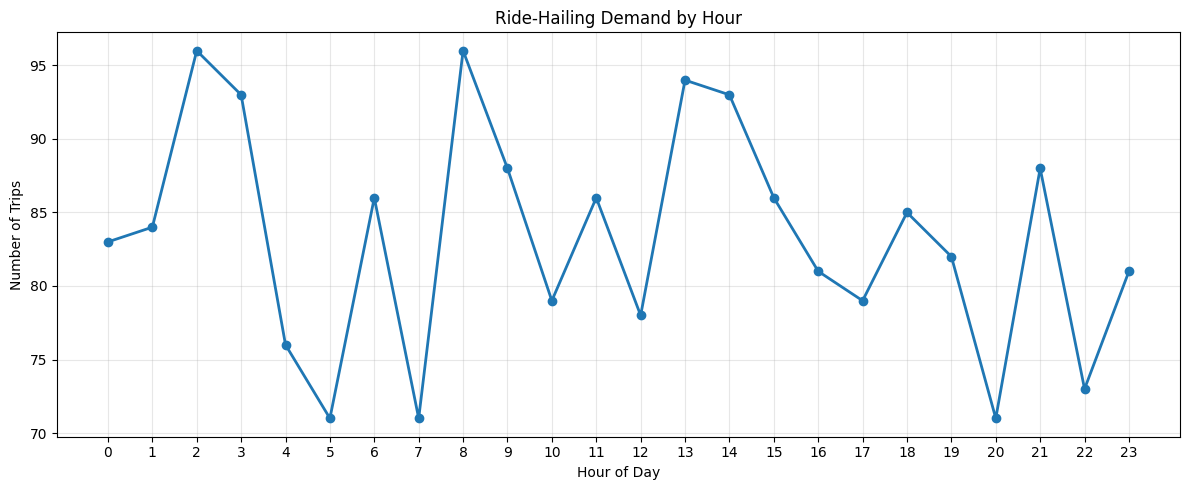

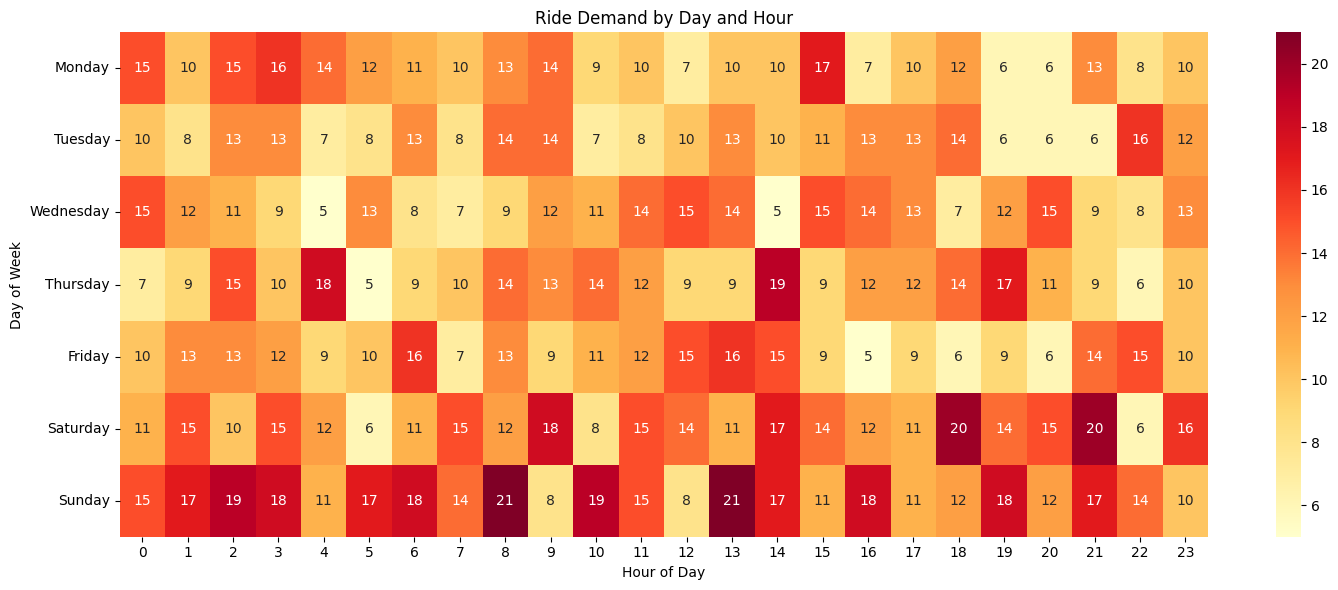

In [33]:


import matplotlib.pyplot as plt
import seaborn as sns


hourly_trips = (
    df.groupby("Hour")["Trip_ID"]
    .count()
)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_trips.index,
    hourly_trips.values,
    marker="o",
    linewidth=2
)

plt.title("Ride-Hailing Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------
# 2. DAY VS HOUR HEATMAP
# ------------------------------------------

day_hour = pd.crosstab(
    df["Day_of_Week"],
    df["Hour"]
)

day_hour = day_hour.reindex([
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
])

plt.figure(figsize=(15, 6))

sns.heatmap(
    day_hour,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Ride Demand by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.show()

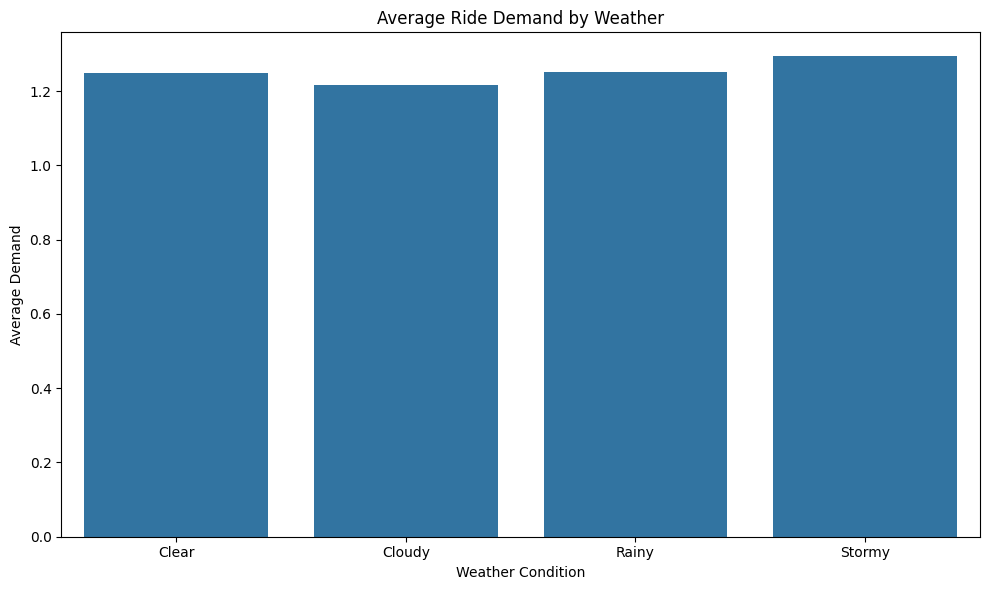

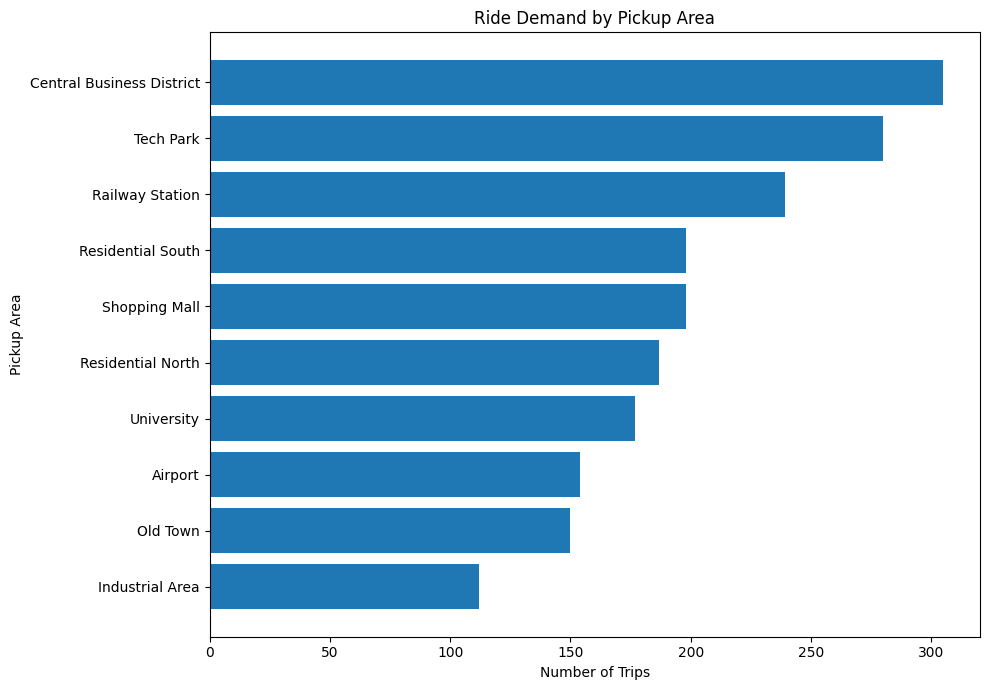

In [34]:


weather_order = [
    "Clear",
    "Cloudy",
    "Rainy",
    "Stormy"
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Weather",
    y="Demand",
    order=weather_order,
    estimator="mean",
    errorbar=None
)

plt.title("Average Ride Demand by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Average Demand")

plt.tight_layout()
plt.show()



area_trips = (
    df.groupby("Pickup_Area")["Trip_ID"]
    .count()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    area_trips.index,
    area_trips.values
)

plt.title("Ride Demand by Pickup Area")
plt.xlabel("Number of Trips")
plt.ylabel("Pickup Area")

plt.tight_layout()
plt.show()

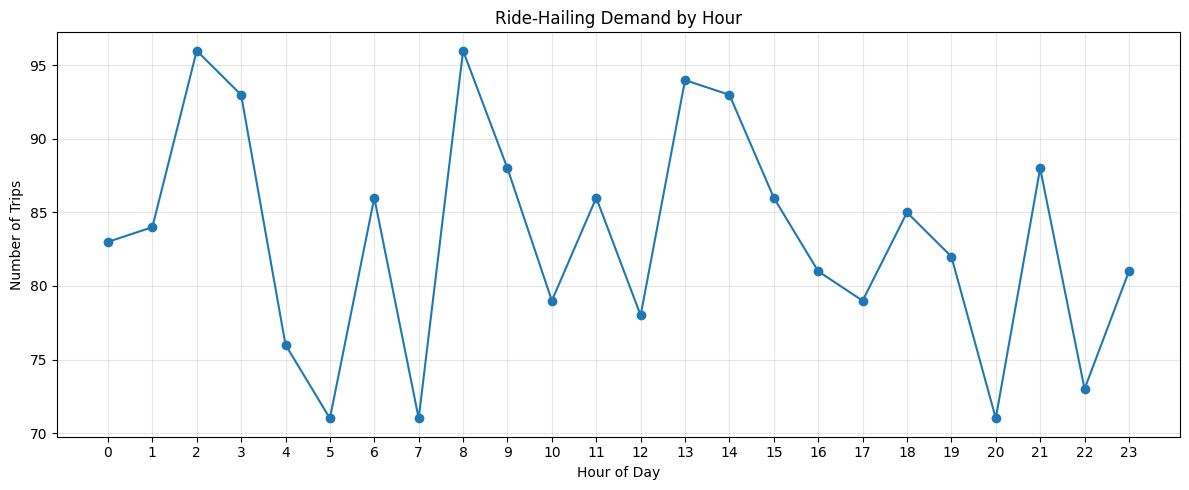

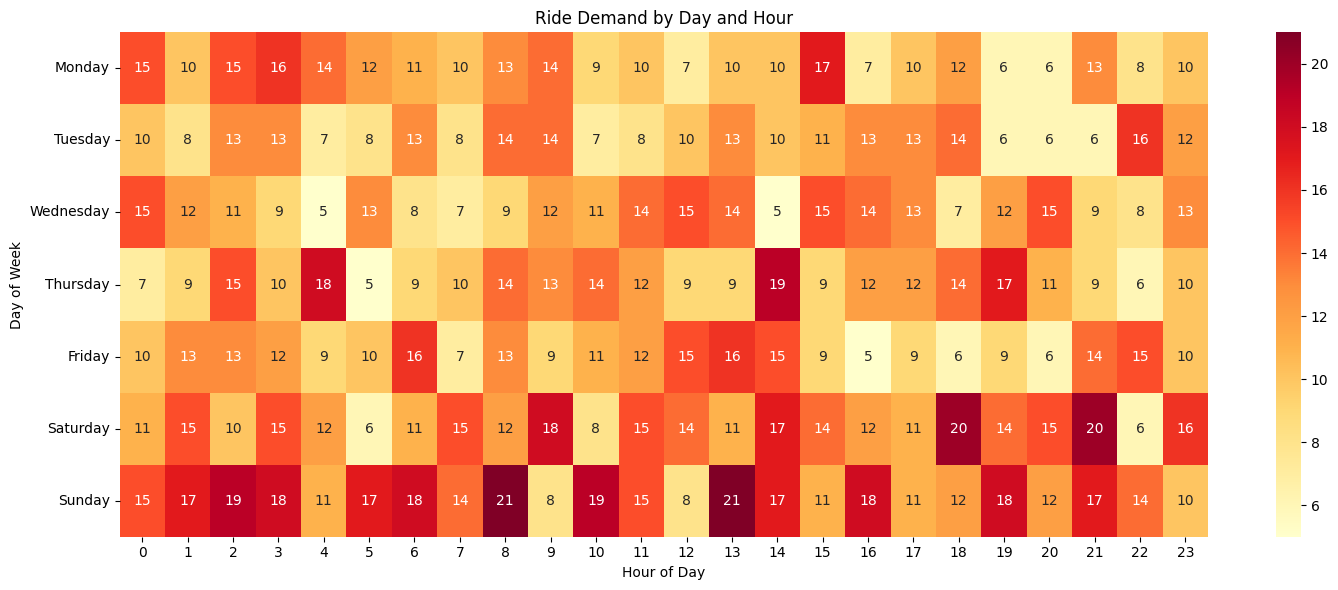

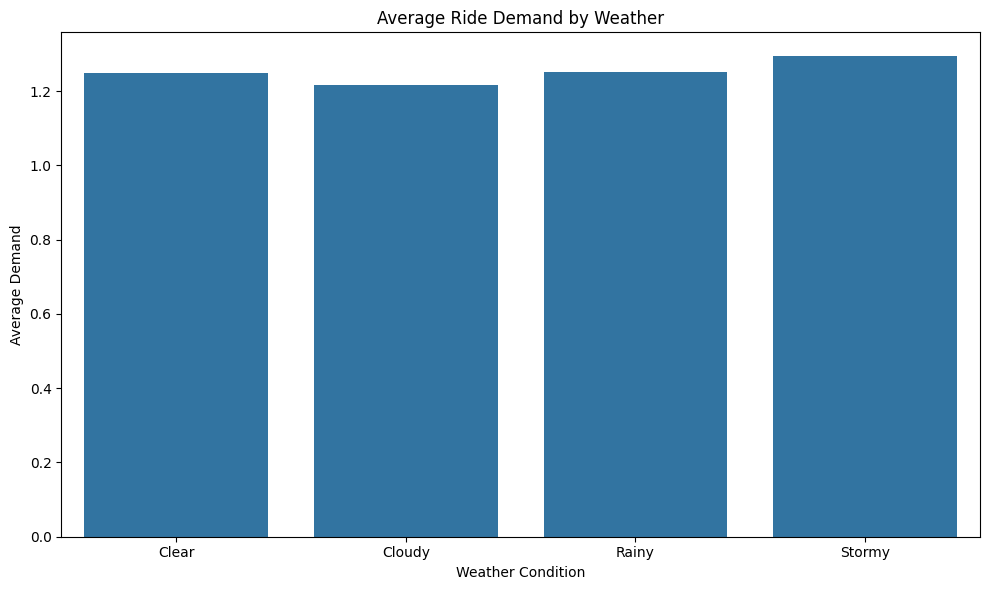

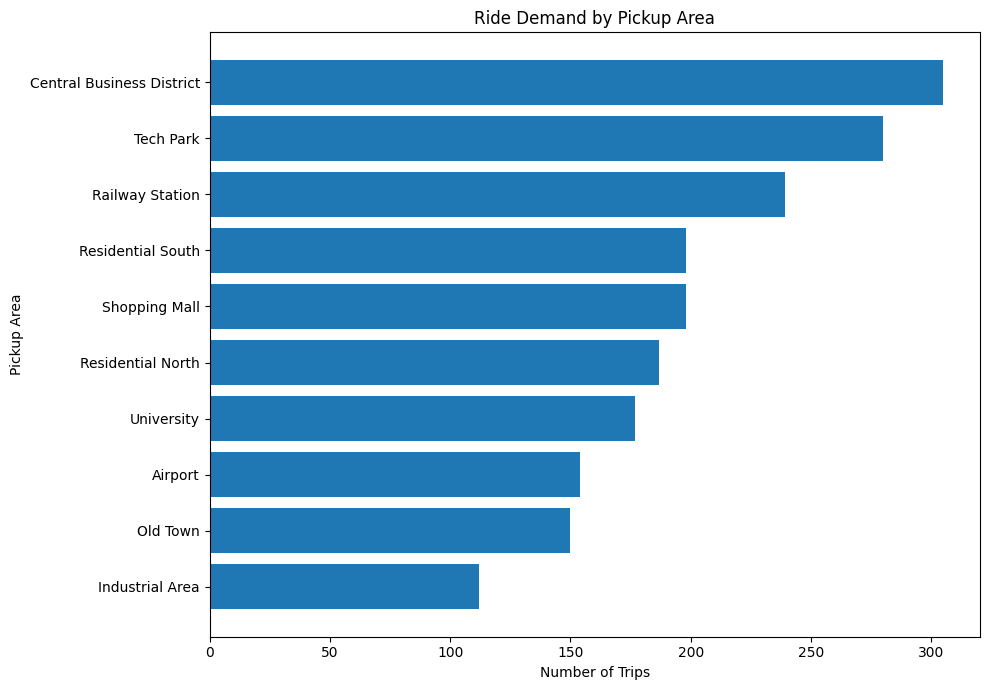

All 4 visualizations saved successfully!


In [35]:

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_trips.index,
    hourly_trips.values,
    marker="o"
)

plt.title("Ride-Hailing Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "01_hourly_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(15, 6))

sns.heatmap(
    day_hour,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Ride Demand by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.savefig(
    "02_day_hour_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Weather",
    y="Demand",
    order=weather_order,
    estimator="mean",
    errorbar=None
)

plt.title("Average Ride Demand by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Average Demand")

plt.tight_layout()
plt.savefig(
    "03_weather_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(10, 7))

plt.barh(
    area_trips.index,
    area_trips.values
)

plt.title("Ride Demand by Pickup Area")
plt.xlabel("Number of Trips")
plt.ylabel("Pickup Area")

plt.tight_layout()
plt.savefig(
    "04_pickup_area_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("All 4 visualizations saved successfully!")

In [36]:
# ==========================================
# STAGE 5 - RANDOM FOREST
# 1. PREPARE ML DATA
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Features used for prediction
# IMPORTANT:
# Demand is NOT included because High_Demand
# was created from Demand.

features = [
    "Hour",
    "Day",
    "Is_Weekend",
    "Fare",
    "Trip_Duration",
    "Average_Fare",
    "Average_Trip_Duration",
    "Pickup_Area",
    "Drop_Area",
    "Weather",
    "Event_Status"
]

X = df[features].copy()
y = df["High_Demand"]

# Convert categorical columns to numerical values
X = pd.get_dummies(
    X,
    columns=[
        "Pickup_Area",
        "Drop_Area",
        "Weather",
        "Event_Status"
    ],
    drop_first=True
)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeatures:")
print(X.columns.tolist())

Feature matrix shape: (2000, 29)
Target shape: (2000,)

Target distribution:
High_Demand
1    2000
Name: count, dtype: int64

Features:
['Hour', 'Day', 'Is_Weekend', 'Fare', 'Trip_Duration', 'Average_Fare', 'Average_Trip_Duration', 'Pickup_Area_Central Business District', 'Pickup_Area_Industrial Area', 'Pickup_Area_Old Town', 'Pickup_Area_Railway Station', 'Pickup_Area_Residential North', 'Pickup_Area_Residential South', 'Pickup_Area_Shopping Mall', 'Pickup_Area_Tech Park', 'Pickup_Area_University', 'Drop_Area_Central Business District', 'Drop_Area_Industrial Area', 'Drop_Area_Old Town', 'Drop_Area_Railway Station', 'Drop_Area_Residential North', 'Drop_Area_Residential South', 'Drop_Area_Shopping Mall', 'Drop_Area_Tech Park', 'Drop_Area_University', 'Weather_Cloudy', 'Weather_Rainy', 'Weather_Stormy', 'Event_Status_No Event']


In [37]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))



rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest model trained successfully!")

Training samples: 1600
Testing samples: 400

Random Forest model trained successfully!


In [39]:
y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("===== RANDOM FOREST RESULTS ====")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))


print("\n===== CLASSIFICATION REPORT ====")

# Dynamically determine labels and target names based on unique classes in y_test
unique_labels = y_test.unique()
current_target_names = []
# Assuming 0 is 'Normal Demand' and 1 is 'High Demand'
if 0 in unique_labels:
    current_target_names.append("Normal Demand")
if 1 in unique_labels:
    current_target_names.append("High Demand")

print(
    classification_report(
        y_test,
        y_pred,
        labels=unique_labels,
        target_names=current_target_names,
        zero_division=0
    )
)
cm = confusion_matrix(y_test, y_pred)

print("\n===== CONFUSION MATRIX ====")
print(cm)

===== RANDOM FOREST RESULTS ====
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

===== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

 High Demand       1.00      1.00      1.00       400

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400


===== CONFUSION MATRIX ====
[[400]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


===== TOP 15 IMPORTANT FEATURES =====
                                  Feature  Importance
0                                    Hour         0.0
1                                     Day         0.0
2                              Is_Weekend         0.0
3                                    Fare         0.0
4                           Trip_Duration         0.0
5                            Average_Fare         0.0
6                   Average_Trip_Duration         0.0
7   Pickup_Area_Central Business District         0.0
8             Pickup_Area_Industrial Area         0.0
9                    Pickup_Area_Old Town         0.0
10            Pickup_Area_Railway Station         0.0
11          Pickup_Area_Residential North         0.0
12          Pickup_Area_Residential South         0.0
13              Pickup_Area_Shopping Mall         0.0
14                  Pickup_Area_Tech Park         0.0


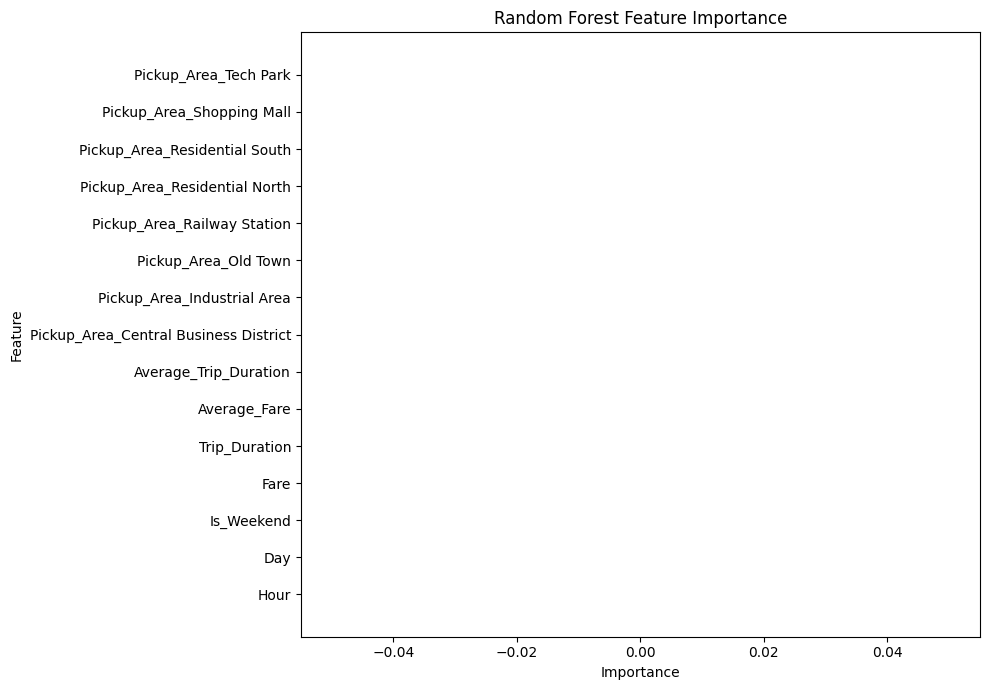

In [40]:
# ==========================================
# 4. FEATURE IMPORTANCE
# ==========================================

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
)

print("===== TOP 15 IMPORTANT FEATURES =====")
print(feature_importance.head(15))


# ------------------------------------------
# VISUALIZE FEATURE IMPORTANCE
# ------------------------------------------

top_features = feature_importance.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [41]:


import joblib

joblib.dump(rf_model, "random_forest_ride_demand.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [42]:
print("=" * 70)
print("RIDE-HAILING DEMAND ANALYSIS - FINAL BUSINESS INSIGHTS")
print("=" * 70)

area_summary = (
    df.groupby("Pickup_Area")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean"),
        Average_Fare=("Fare", "mean"),
        Average_Duration=("Trip_Duration", "mean")
    )
    .sort_values("Total_Trips", ascending=False)
)

top_area = area_summary.index[0]
top_area_trips = area_summary.iloc[0]["Total_Trips"]

print("\n1. HIGH-DEMAND LOCATION")
print("-" * 40)
print(f"Highest-demand pickup area: {top_area}")
print(f"Total trips: {int(top_area_trips)}")

hour_summary = (
    df.groupby("Hour")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean")
    )
    .sort_values("Total_Trips", ascending=False)
)

peak_hour = hour_summary.index[0]
peak_hour_trips = hour_summary.iloc[0]["Total_Trips"]

print("\n2. PEAK DEMAND HOUR")
print("-" * 40)
print(f"Peak hour: {peak_hour}:00")
print(f"Trips during peak hour: {int(peak_hour_trips)}")

day_summary = (
    df.groupby("Day_of_Week")["Trip_ID"]
    .count()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

peak_day = day_summary.idxmax()
peak_day_trips = day_summary.max()

print("\n3. PEAK DAY")
print("-" * 40)
print(f"Highest-demand day: {peak_day}")
print(f"Total trips: {int(peak_day_trips)}")

weather_summary = (
    df.groupby("Weather")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean"),
        Average_Fare=("Fare", "mean")
    )
    .sort_values("Average_Demand", ascending=False)
)

highest_weather = weather_summary.index[0]
highest_weather_demand = weather_summary.iloc[0]["Average_Demand"]

lowest_weather = weather_summary.index[-1]
lowest_weather_demand = weather_summary.iloc[-1]["Average_Demand"]

print("\n4. WEATHER IMPACT")
print("-" * 40)
print(f"Highest average demand occurs during: {highest_weather}")
print(f"Average demand: {highest_weather_demand:.2f}")
print(f"Lowest average demand occurs during: {lowest_weather}")
print(f"Average demand: {lowest_weather_demand:.2f}")

event_summary = (
    df.groupby("Event_Status")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Demand=("Demand", "mean"),
        Average_Fare=("Fare", "mean")
    )
)

event_demand = event_summary.loc["Event", "Average_Demand"]
no_event_demand = event_summary.loc["No Event", "Average_Demand"]

event_percentage_change = (
    (event_demand - no_event_demand)
    / no_event_demand
) * 100

print("\n5. EVENT IMPACT")
print("-" * 40)
print(f"Average demand during events: {event_demand:.2f}")
print(f"Average demand without events: {no_event_demand:.2f}")
print(f"Demand difference during events: {event_percentage_change:.2f}%")

route_summary = (
    df.groupby("Route")
    .agg(
        Total_Trips=("Trip_ID", "count"),
        Average_Duration=("Trip_Duration", "mean"),
        Average_Fare=("Fare", "mean")
    )
    .sort_values("Average_Duration", ascending=False)
)

slowest_route = route_summary.index[0]
slowest_duration = route_summary.iloc[0]["Average_Duration"]

print("\n6. SLOWEST ROUTE")
print("-" * 40)
print(f"Slowest route: {slowest_route}")
print(f"Average trip duration: {slowest_duration:.2f} minutes")

area_hour = (
    df.groupby([
        "Pickup_Area",
        "Hour"
    ])
    .size()
    .reset_index(name="Trips")
    .sort_values("Trips", ascending=False)
)

best_position = area_hour.iloc[0]

print("\n7. BEST DRIVER POSITIONING OPPORTUNITY")
print("-" * 40)
print(f"Pickup area: {best_position['Pickup_Area']}")
print(f"Peak hour: {int(best_position['Hour'])}:00")
print(f"Observed trips: {int(best_position['Trips'])}")

print("\n8. RANDOM FOREST MODEL")
print("-" * 40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

top_model_features = feature_importance.head(5)

print("\n9. TOP PREDICTIVE FEATURES")
print("-" * 40)

for _, row in top_model_features.iterrows():
    print(f"{row['Feature']}: {row['Importance']:.4f}")

print("=" * 70)
print("PRACTICAL ACTION PLAN")
print("=" * 70)

print(f"""
1. DRIVER POSITIONING
   Position additional drivers around:
   {best_position['Pickup_Area']}
   during approximately {int(best_position['Hour'])}:00.

2. PEAK-HOUR PREPARATION
   Increase driver availability around:
   {peak_hour}:00.

3. HIGH-DEMAND LOCATIONS
   Prioritize driver allocation toward:
   {top_area}

4. WEATHER RESPONSE
   Monitor weather conditions, particularly:
   {highest_weather}

5. EVENT MANAGEMENT
   Events show a {event_percentage_change:.2f}% difference
   in average demand compared with non-event periods.

6. ROUTE MONITORING
   Monitor:
   {slowest_route}
   because it has the highest average travel duration.

7. FORECASTING SUPPORT
   Use the Random Forest model to identify periods
   likely to experience high demand and support
   proactive driver allocation.
""")

final_summary = pd.DataFrame({
    "Metric": [
        "Total Trips",
        "Highest Demand Area",
        "Peak Hour",
        "Peak Day",
        "Highest Demand Weather",
        "Slowest Route",
        "Best Driver Position"
    ],
    "Result": [
        len(df),
        top_area,
        f"{peak_hour}:00",
        peak_day,
        highest_weather,
        slowest_route,
        f"{best_position['Pickup_Area']} at {int(best_position['Hour'])}:00"
    ]
})

print("\nFINAL SUMMARY")
print("-" * 70)
print(final_summary.to_string(index=False))

print("\n" + "=" * 70)
print("STAGE 6 COMPLETED")
print("=" * 70)

RIDE-HAILING DEMAND ANALYSIS - FINAL BUSINESS INSIGHTS

1. HIGH-DEMAND LOCATION
----------------------------------------
Highest-demand pickup area: Central Business District
Total trips: 305

2. PEAK DEMAND HOUR
----------------------------------------
Peak hour: 2:00
Trips during peak hour: 96

3. PEAK DAY
----------------------------------------
Highest-demand day: Sunday
Total trips: 361

4. WEATHER IMPACT
----------------------------------------
Highest average demand occurs during: Stormy
Average demand: 1.29
Lowest average demand occurs during: Cloudy
Average demand: 1.22

5. EVENT IMPACT
----------------------------------------
Average demand during events: 1.22
Average demand without events: 1.25
Demand difference during events: -2.56%

6. SLOWEST ROUTE
----------------------------------------
Slowest route: Residential North -> Tech Park
Average trip duration: 34.25 minutes

7. BEST DRIVER POSITIONING OPPORTUNITY
----------------------------------------
Pickup area: Central B